In [1]:
!pip install ultralytics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 873.1/873.1 kB 5.5 MB/s eta 0:00:00


In [2]:
!pip install roboflow

from roboflow import Roboflow
rf = Roboflow(api_key="2ffl1zZqwCdjI4cj61VQ")
project = rf.workspace("work-r9avx").project("sc_save")
version = project.version(2)
dataset = version.download("yolov9")


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.3/80.3 kB 1.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 66.8/66.8 kB 3.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.5/54.5 kB 3.1 MB/s eta 0:00:00
  Attempting uninstall: idna
    Found existing installation: idna 3.10
    Uninstalling idna-3.10:
      Successfully uninstalled idna-3.10
loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to SC_SAVE-2 in yolov9:: 100%|██████████| 3028/3028 [00:00<00:00, 7984.59it/s]


In [3]:
import torch
from ultralytics import YOLO
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_fscore_support, confusion_matrix, precision_recall_curve
import seaborn as sns
import numpy as np


In [ ]:
from ultralytics import YOLO

# Load the YOLOv8 model (you can choose a model variant like yolov8s, yolov8m, etc.)
model = YOLO('yolov10s.pt')  # You can also use other weights like 'yolov8n.pt'

model.train(
    data='/content/SC_SAVE-2/data.yaml',       # Path to your dataset configuration file
    epochs=600,              # Number of training epochs
    imgsz=640,              # Image size
    batch=16,               # Batch size
    lr0=0.001,              # Initial learning rate
    lrf=0.1,                # Final learning rate as a fraction of lr0
    momentum=0.937,         # Momentum
    weight_decay=0.0005,    # Weight decay
    device='0'              # Use '0' for GPU or 'cpu' if you don't have a GPU
)  # Use device='cpu' if GPU is not available


Ultralytics YOLOv8.2.90 🚀 Python-3.10.12 torch-2.4.0+cu121 CUDA:0 (NVIDIA A100-SXM4-40GB, 40514MiB)
engine/trainer: task=detect, mode=train, model=yolov10s.pt, data=/content/SC_SAVE-2/data.yaml, epochs=600, time=None, patience=100, batch=16, imgsz=640, save=True, save_period=-1, cache=False, device=0, workers=8, project=None, name=train2, exist_ok=False, pretrained=True, optimizer=auto, verbose=True, seed=0, deterministic=True, single_cls=False, rect=False, cos_lr=False, close_mosaic=10, resume=False, amp=True, fraction=1.0, profile=False, freeze=None, multi_scale=False, overlap_mask=True, mask_ratio=4, dropout=0.0, val=True, split=val, save_json=False, save_hybrid=False, conf=None, iou=0.7, max_det=300, half=False, dnn=False, plots=True, source=None, vid_stride=1, stream_buffer=False, visualize=False, augment=False, agnostic_nms=False, classes=None, retina_masks=False, embed=None, show=False, save_frames=False, save_txt=False, save_conf=False, save_crop=False, show_labels=True, show_c

100%|██████████| 755k/755k [00:00<00:00, 89.0MB/s]


Overriding model.yaml nc=80 with nc=3

                   from  n    params  module                                       arguments                     
  0                  -1  1       928  ultralytics.nn.modules.conv.Conv             [3, 32, 3, 2]                 
  1                  -1  1     18560  ultralytics.nn.modules.conv.Conv             [32, 64, 3, 2]                
  2                  -1  1     29056  ultralytics.nn.modules.block.C2f             [64, 64, 1, True]             
  3                  -1  1     73984  ultralytics.nn.modules.conv.Conv             [64, 128, 3, 2]               
  4                  -1  2    197632  ultralytics.nn.modules.block.C2f             [128, 128, 2, True]           
  5                  -1  1     36096  ultralytics.nn.modules.block.SCDown          [128, 256, 3, 2]              
  6                  -1  2    788480  ultralytics.nn.modules.block.C2f             [256, 256, 2, True]           
  7                  -1  1    137728  ultralytics

100%|██████████| 6.25M/6.25M [00:00<00:00, 326MB/s]


AMP: checks passed ✅


...

                   all        303        454      0.779      0.566      0.652      0.362
EarlyStopping: Training stopped early as no improvement observed in last 100 epochs. Best results observed at epoch 416, best model saved as best.pt.
To update EarlyStopping(patience=100) pass a new patience value, i.e. `patience=300` or use `patience=0` to disable EarlyStopping.



516 epochs completed in 1.622 hours.
Optimizer stripped from runs/detect/train2/weights/last.pt, 16.6MB
Optimizer stripped from runs/detect/train2/weights/best.pt, 16.6MB

Validating runs/detect/train2/weights/best.pt...
Ultralytics YOLOv8.2.90 🚀 Python-3.10.12 torch-2.4.0+cu121 CUDA:0 (NVIDIA A100-SXM4-40GB, 40514MiB)
YOLOv10s summary (fused): 293 layers, 8,037,282 parameters, 0 gradients, 24.5 GFLOPs


                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100%|██████████| 10/10 [00:02<00:00,  3.51it/s]


                   all        303        454      0.791      0.581      0.671      0.381
           acrochordon         55        120      0.727      0.392      0.483      0.266
          dermatofibro        151        168      0.897       0.81      0.897      0.525
             lichenoid         97        166      0.748      0.542      0.634      0.352
Speed: 0.1ms preprocess, 3.2ms inference, 0.0ms loss, 0.2ms postprocess per image
Results saved to runs/detect/train2


ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0, 1, 2])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7ff3a5bab340>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
          0.04

In [ ]:
from ultralytics import YOLO  # Ensure you have the right package

# Load the model
model = YOLO("/content/runs/detect/train2/weights/best.pt")

# Validate the model on the dataset
result = model.val(data="/content/SC_SAVE-2/data.yaml", imgsz=640)

Ultralytics YOLOv8.2.90 🚀 Python-3.10.12 torch-2.4.0+cu121 CUDA:0 (NVIDIA A100-SXM4-40GB, 40514MiB)
YOLOv10s summary (fused): 293 layers, 8,037,282 parameters, 0 gradients, 24.5 GFLOPs


val: Scanning /content/SC_SAVE-2/valid/labels.cache... 303 images, 0 backgrounds, 0 corrupt: 100%|██████████| 303/303 [00:00<?, ?it/s]
os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100%|██████████| 19/19 [00:03<00:00,  5.68it/s]


                   all        303        454      0.792      0.583      0.671      0.381
           acrochordon         55        120      0.723      0.392      0.483      0.266
          dermatofibro        151        168      0.901      0.814      0.897      0.526
             lichenoid         97        166      0.751      0.544      0.633      0.351
Speed: 0.2ms preprocess, 2.6ms inference, 0.0ms loss, 0.1ms postprocess per image
Results saved to runs/detect/val


In [4]:
from ultralytics import YOLO  # Ensure you have the right package

# Load the model
model = YOLO("/content/best.pt")

# Test the model on the dataset
result = model.val(data="/content/SC_SAVE-2/data.yaml", imgsz=640)

Ultralytics YOLOv8.2.97 🚀 Python-3.10.12 torch-2.4.0+cu121 CUDA:0 (NVIDIA A100-SXM4-40GB, 40514MiB)
YOLOv10s summary (fused): 293 layers, 8,037,282 parameters, 0 gradients, 24.5 GFLOPs


100%|██████████| 755k/755k [00:00<00:00, 15.3MB/s]
val: Scanning /content/SC_SAVE-2/test/labels... 151 images, 0 backgrounds, 0 corrupt: 100%|██████████| 151/151 [00:00<00:00, 1107.88it/s]


val: New cache created: /content/SC_SAVE-2/test/labels.cache


                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100%|██████████| 10/10 [00:03<00:00,  2.97it/s]


                   all        151        222       0.85      0.603      0.714      0.396
           acrochordon         27         44      0.757      0.497      0.625      0.341
          dermatofibro         73         82       0.92      0.793      0.883      0.497
             lichenoid         51         96      0.873      0.521      0.633      0.351
Speed: 1.5ms preprocess, 2.8ms inference, 0.0ms loss, 0.9ms postprocess per image
Results saved to runs/detect/val


In [5]:

import shutil

# Create a zip file of the directory
shutil.make_archive("/content/runs/detect/val", 'zip', "/content/runs/detect/val")

# Download the zip file
from google.colab import files
files.download("/content/runs/detect/val.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# Assuming result is from model.val()
cm_object = result.confusion_matrix  # Get the ConfusionMatrix object

# Convert to a numpy array
cm_array = cm_object.matrix  # Access the matrix attribute to get the numpy array

# Print the confusion matrix
print("Confusion Matrix:")
print(cm_array)


Confusion Matrix:
[[         52           0           1           9]
 [          0         137           2           6]
 [          1           9          94           6]
 [         67          22          69           0]]


In [ ]:
import numpy as np
from sklearn.metrics import precision_score, recall_score, f1_score, accuracy_score, average_precision_score
from sklearn.preprocessing import label_binarize

# Provided confusion matrix
conf_matrix = np.array(cm_array[:-1,:-1])

# Class names
class_names = ['acrochordon', 'dermatofibro', 'lichenoid']
n_classes = len(class_names)

# Calculate True Positives, False Positives, False Negatives, and True Negatives
TP = np.diag(conf_matrix)
FP = np.sum(conf_matrix, axis=0) - TP
FN = np.sum(conf_matrix, axis=1) - TP
TN = np.sum(conf_matrix) - (TP + FP + FN)

# Precision, Recall, F1 Score per class
precision = TP / (TP + FP)
recall = TP / (TP + FN)
f1 = 2 * (precision * recall) / (precision + recall)

# Overall metrics (macro average)
overall_precision = np.mean(precision)
overall_recall = np.mean(recall)
overall_f1 = np.mean(f1)

# Accuracy
accuracy = np.sum(TP) / np.sum(conf_matrix)

# Display per-class metrics
print("Precision per class:", dict(zip(class_names, precision)),"\n")
print("Recall per class:", dict(zip(class_names, recall)),"\n")
print("F1 Score per class:", dict(zip(class_names, f1)),"\n")
print("Accuracy:", accuracy,"\n")

# Display overall metrics
print("Overall Precision (Macro Average):", overall_precision,"\n")
print("Overall Recall (Macro Average):", overall_recall,"\n")
print("Overall F1 Score (Macro Average):", overall_f1,"\n")

# Example true labels and predicted class probabilities
true_labels = []
pred_probs = []

for true_class in range(n_classes):
    for pred_class in range(n_classes):
        num_samples = int(conf_matrix[true_class, pred_class]) # Convert num_samples to integer
        true_labels.extend([true_class] * num_samples)
        pred_probs.extend([pred_class] * num_samples)

# Convert to numpy arrays
true_labels = np.array(true_labels)
pred_probs = np.array(pred_probs)

# Binarize the true labels and predicted scores
true_labels_binarized = label_binarize(true_labels, classes=np.arange(n_classes))
pred_probs_binarized = label_binarize(pred_probs, classes=np.arange(n_classes))

# Compute average precision for each class
ap_scores = []
for i in range(n_classes):
    ap = average_precision_score(true_labels_binarized[:, i], pred_probs_binarized[:, i])
    ap_scores.append(ap)

# Mean Average Precision (mAP)
map50 = np.mean(ap_scores)
map50_90 = map50  # Adjust according to thresholds if required

print("mAP@50:", map50,"\n")
print("mAP@50-90:", map50_90,"\n")

Precision per class: {'acrochordon': 0.9811320754716981, 'dermatofibro': 0.9383561643835616, 'lichenoid': 0.9690721649484536} 

Recall per class: {'acrochordon': 0.9811320754716981, 'dermatofibro': 0.9856115107913669, 'lichenoid': 0.9038461538461539} 

F1 Score per class: {'acrochordon': 0.9811320754716981, 'dermatofibro': 0.9614035087719297, 'lichenoid': 0.9353233830845771} 

Accuracy: 0.956081081081081 

Overall Precision (Macro Average): 0.9628534682679044 

Overall Recall (Macro Average): 0.9568632467030729 

Overall F1 Score (Macro Average): 0.9592863224427349 

mAP@50: 0.9357619514549401 

mAP@50-90: 0.9357619514549401 



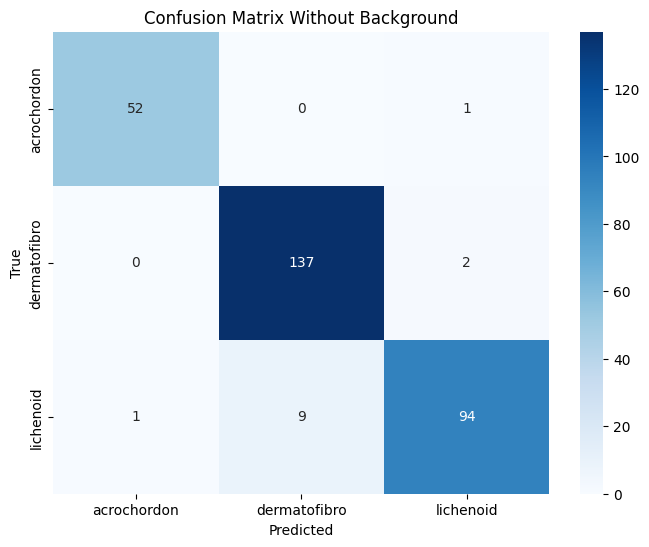

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

labels = ['acrochordon', 'dermatofibro', 'lichenoid']  # Adjust based on your actual class labels

plt.figure(figsize=(8, 6))
sns.heatmap(cm_array[:-1, :-1], annot=True, fmt="g", cmap="Blues", xticklabels=labels, yticklabels=labels)
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion Matrix Without Background")
plt.show()


In [ ]:
# Function to calculate precision and recall using True Positives, False Positives, and False Negatives
def calculate_precision_recall(TP, FP, FN):
    # Precision calculation
    precision = TP / (TP + FP) if (TP + FP) > 0 else 0
    # Recall calculation
    recall = TP / (TP + FN) if (TP + FN) > 0 else 0

    return precision, recall

# Values for each class
classes = {
    "Acrochordon": {"TP": 52, "FP": 1, "FN": 2},
    "Dermatofibro": {"TP": 137, "FP": 11, "FN": 2},
    "Lichenoid": {"TP": 94, "FP": 3, "FN": 10}
}

# Calculate and print precision and recall for each class
for class_name, values in classes.items():
    precision, recall = calculate_precision_recall(values['TP'], values['FP'], values['FN'])
    print(f"{class_name}: Precision = {precision:.2f}, Recall = {recall:.2f}")


Acrochordon: Precision = 0.98, Recall = 0.96
Dermatofibro: Precision = 0.93, Recall = 0.99
Lichenoid: Precision = 0.97, Recall = 0.90


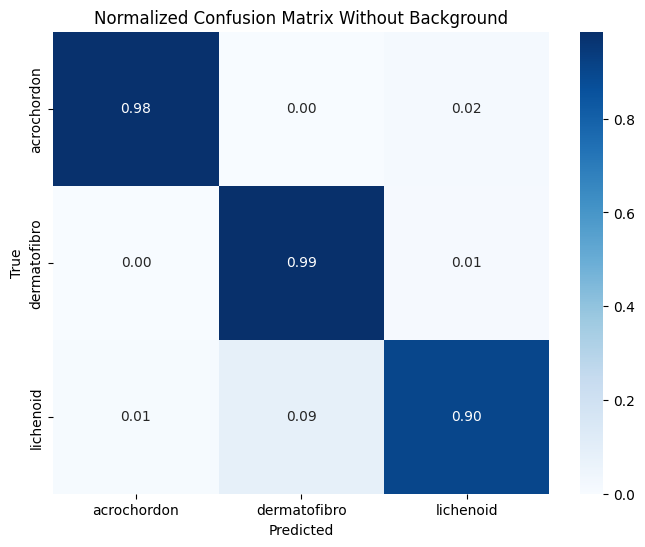

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

cm_no_bg = cm_array[:-1, :-1]

# Normalize the confusion matrix
cm_no_bg_normalized = cm_no_bg.astype('float') / cm_no_bg.sum(axis=1)[:, np.newaxis]

# Print the normalized confusion matrix without the background
# print("Normalized Confusion Matrix (Without Background):")
# print(cm_no_bg_normalized)

# Visualization of the normalized confusion matrix
labels = ['acrochordon', 'dermatofibro', 'lichenoid']  # Adjust based on your actual class labels

plt.figure(figsize=(8, 6))
sns.heatmap(cm_no_bg_normalized, annot=True, fmt=".2f", cmap="Blues", xticklabels=labels, yticklabels=labels)
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Normalized Confusion Matrix Without Background")
plt.show()


In [ ]:
!zip -r /content/runs.zip /content/runs
from google.colab import files
files.download("/content/runs.zip")

NotImplementedError: A UTF-8 locale is required. Got ANSI_X3.4-1968

In [ ]:
import shutil

# Create a zip file of the directory
shutil.make_archive("/content/runs", 'zip', "/content/runs")

# Download the zip file
from google.colab import files
files.download("/content/runs.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>